<a href="https://colab.research.google.com/github/BrunoCapron/ESQ724-fundamentos_aprendizado_maquina/blob/main/Aprendizado_Supervisionado/Random_Forest/Classificacao_vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problema de classificação de vinhos de diferentes cultivares conforme perfil químico (álcool, ácido málico, fenóis, flavonoides etc.)

Importação dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print(X.shape)
print(y.value_counts().sort_index())   # distribuição das classes
X.head()

(178, 13)
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Separação dos conjuntos de treino e teste

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

Uma árvore isolada vs. floresta (validação cruzada)

In [3]:
arvore = DecisionTreeClassifier(random_state=42)
floresta = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

for nome, modelo in [("Árvore de decisão", arvore), ("Random Forest", floresta)]:
    scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring="accuracy")
    print(f"{nome}: {scores.mean():.3f} ± {scores.std():.3f}")

Árvore de decisão: 0.895 ± 0.076
Random Forest: 0.970 ± 0.015


Avaliação no teste (precisão, revocação, F1)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



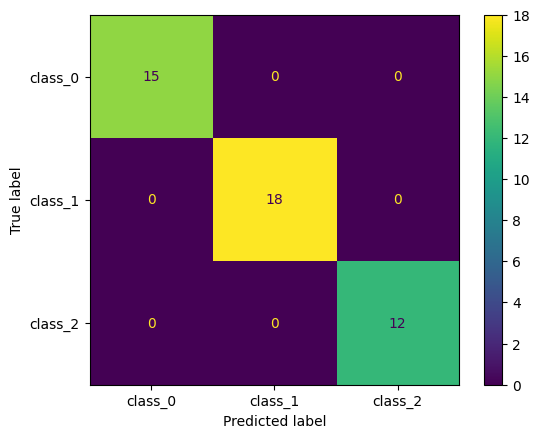

In [6]:
floresta = RandomForestClassifier(
    n_estimators=200, random_state=42, n_jobs=-1
)
floresta.fit(X_train, y_train)

y_pred = floresta.predict(X_test)
print(classification_report(y_test, y_pred, target_names=wine.target_names))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=wine.target_names)
plt.show()

Importância dos atributos

A importância baseada em redução de impureza (mean decrease in impurity, MDI, ou “importância de Gini”) mede o quanto cada atributo contribuiu, ao longo de toda a floresta, para reduzir a impureza dos nós.

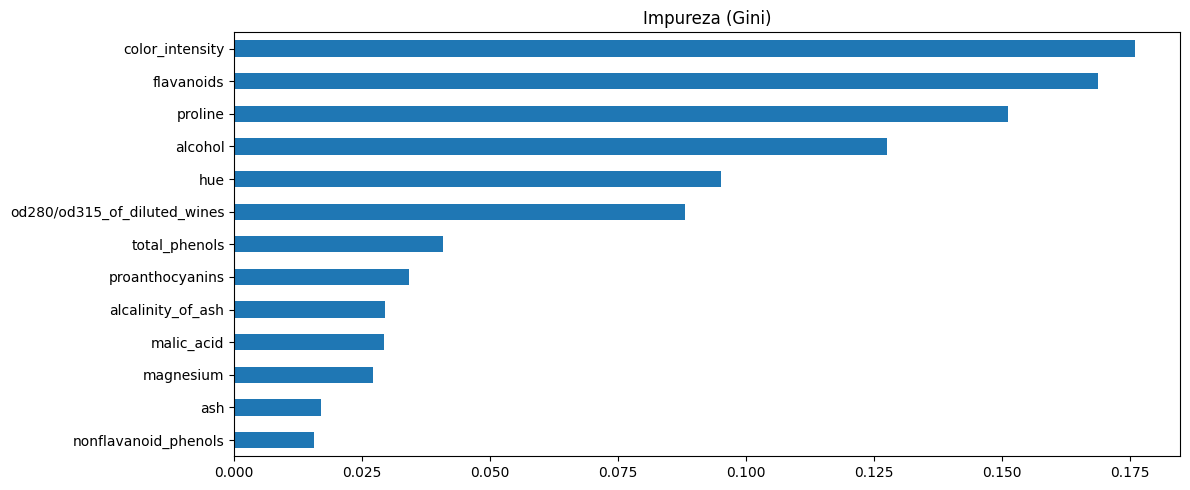

In [11]:
# Importância baseada em redução de impureza (rápida, mas pode ser enviesada)
imp_gini = pd.Series(floresta.feature_importances_, index=X.columns)

fig, axs = plt.subplots(1, 1, figsize=(12, 5), sharey=True)
imp_gini.sort_values().plot.barh(ax=axs, title="Impureza (Gini)")
plt.tight_layout()
plt.show()

efeito do número de árvores

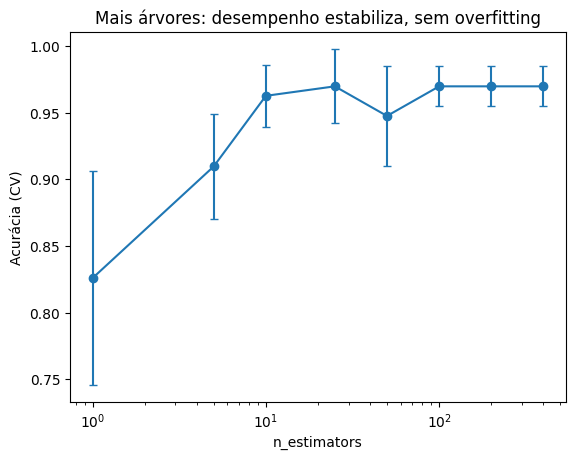

In [12]:
ns = [1, 5, 10, 25, 50, 100, 200, 400]
medias, desvios = [], []
for n in ns:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    s = cross_val_score(rf, X_train, y_train, cv=5)
    medias.append(s.mean()); desvios.append(s.std())

plt.errorbar(ns, medias, yerr=desvios, marker="o", capsize=3)
plt.xscale("log")
plt.xlabel("n_estimators"); plt.ylabel("Acurácia (CV)")
plt.title("Mais árvores: desempenho estabiliza, sem overfitting")
plt.show()

Efeito de max_features

In [13]:
for mf in [1, 3, "sqrt", 13]:
    rf = RandomForestClassifier(n_estimators=200, max_features=mf,
                                random_state=42, n_jobs=-1)
    s = cross_val_score(rf, X_train, y_train, cv=5)
    print(f"max_features={mf!s:>5}: {s.mean():.3f} ± {s.std():.3f}")

max_features=    1: 0.977 ± 0.019
max_features=    3: 0.970 ± 0.015
max_features= sqrt: 0.970 ± 0.015
max_features=   13: 0.903 ± 0.069
